# 03 · 微服务基础（微服务01）


## 本章来源与学习路线

本篇依据百度网盘 **`我的资源/微服务01.pptx`**，共 **66 页，无隐藏页**。这是「微服务全套」的第三篇笔记，对应用户指定的 `微服务01` 课件。整理日期：2026-10-09。

课件预览：[微服务01](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2F%E5%BE%AE%E6%9C%8D%E5%8A%A101.pptx&fsid=383753848538865&size=2709423&view_from=personal_file&md5=7e56902e2he1b91b2382c60f820e05f8&share=0&client=web&scene=main)。

| 阶段 | 课件页码 | 解决的问题 |
| --- | --- | --- |
| 认识微服务 | 1—20 | 单体与微服务如何取舍，Spring Cloud 提供什么 |
| 微服务拆分 | 21—34 | 如何拆出商品、购物车服务，如何跨服务查询商品 |
| 服务治理 | 35—45 | 实例地址会变化，怎样注册、发现和选择实例 |
| OpenFeign | 46—66 | 如何声明远程接口、复用连接、共享契约与配置日志 |

本篇沿着 **购物车查询当前商品信息** 的业务链路理解技术：本地方法调用 → HTTP 远程调用 → 注册发现与负载均衡 → OpenFeign 声明式调用。

**版本约定**：示例按 Java 11、Spring Boot 2.x 与课件 Spring Cloud 2021.0.x 时代的配置方式整理。课件未给出完整父 POM 和所有组件的精确版本，本文不虚构项目版本组合。新项目应核对 Spring Boot、Spring Cloud、Spring Cloud Alibaba 及 Nacos 的兼容矩阵。

**示例说明**：标注“课件方案”的内容来自课件；“整理示例”是为连贯阅读而重建的代码；“补充/改进”说明运行边界。已核对 PPT 文字与关键截图，未读取完整课程源码或运行微服务工程。文中 `@Data`、`@RequiredArgsConstructor` 等为 Lombok 注解，常规 import 省略，关键同名类型会单独说明。


## 1. 单体架构的收益与限制

项目早期最重要的通常是快速实现业务。把商品、用户、购物车、订单等模块放在一个可部署应用里，能降低开发和部署门槛。（课件第 13 页）

**单体架构**：多个业务模块在一个应用中开发，通常打成一个包，作为整体部署。

```text
黑马商城应用
├── 商品模块
├── 用户模块
├── 购物车模块
├── 订单模块
└── 支付模块
       ↓
一个应用进程 / 一个部署包
```

| 维度 | 单体的收益 | 规模扩大后的问题 |
| --- | --- | --- |
| 代码调用 | 模块间直接调用 Java 方法 | 依赖关系容易交织 |
| 数据操作 | 本地事务和查询较直接 | 数据边界逐渐模糊 |
| 团队协作 | 小团队沟通链路短 | 多团队修改同一应用，协调增多 |
| 发布 | 一次构建和部署 | 小改动也可能触发整体发布 |
| 扩容与故障 | 运维对象较少 | 难以独立扩容热点模块，故障影响范围可能较大 |

单体也可以做模块化、集群和高可用，不能把“单体”直接等同于“必然不可用”。课件指出的是大型单体常见的协作、发布和隔离问题。


## 2. 微服务架构与服务自治

当不同业务需要独立发布、扩容和团队协作时，可以把一个大应用拆成多个职责明确的服务。（课件第 3—8、15—16 页）

**微服务是一种架构风格**：用多个专注于业务职责、能够独立运行和部署的服务，协作完成整体业务。

| 特征 | 具体含义 | 判断标准 |
| --- | --- | --- |
| 职责聚焦 | 服务负责相对完整的业务能力 | 商品服务管理商品及相关规则 |
| 团队自治 | 团队能够管理自己的业务实现 | 减少每次修改都跨团队协调 |
| 服务自治 | 服务能独立构建、运行、发布 | 不必把所有服务同时升级 |
| 通过契约协作 | 服务之间通过接口或消息交互 | 不依赖对方内部 Mapper、实体和表结构 |

```text
购物车服务 ── 商品查询接口 ──► 商品服务
    │                            │
    ▼                            ▼
购物车数据                    商品数据

两个独立应用，通过约定的接口协作
```

“小”指职责边界清楚，不是代码行数越少越好。把一个类拆成一个进程，反而可能增加网络调用和维护成本。

**代价**：本地调用变成网络调用，带来超时、失败、数据一致性、调用追踪、配置和运维问题。微服务提供独立治理的机会，并不会自动保证业务可用性更高。

课件前面的网关、认证、消息队列、分布式事务、搜索等属于整套课程地图；本篇重点完成拆分、注册发现与同步远程调用，不把后续主题提前混成一套未实现方案。


## 3. Spring Boot、Spring Cloud 与组件分工

拆成多个服务之后，每个服务仍需要 Web、数据访问和配置能力，服务之间还需要注册发现、路由和远程调用。Spring Boot 与 Spring Cloud 解决的层次不同。（课件第 18 页）

| 技术 | 主要作用 |
| --- | --- |
| Spring Boot | 构建一个应用，提供自动配置、依赖管理与运行入口 |
| Spring Cloud | 为分布式系统整合服务发现、调用、网关等能力 |
| Spring Cloud Alibaba | 整合 Nacos、Sentinel 等相关组件 |
| Nacos Server | 独立运行的服务注册发现、配置管理服务端 |

课件列举的组件包括：

| 能力 | 课件举例 | 本篇关注点 |
| --- | --- | --- |
| 服务注册发现 | Eureka、Nacos、Consul | Nacos |
| 远程调用 | OpenFeign、Dubbo | OpenFeign 的 HTTP 调用 |
| 链路监控 | Zipkin、Sleuth | 了解用途 |
| 配置管理 | Spring Cloud Config、Nacos | 后续内容 |
| 统一网关 | Spring Cloud Gateway、Zuul | 后续内容 |
| 流控与降级 | Hystrix、Sentinel | 后续内容 |

这些组件来自不同项目，不代表全部由 Spring Cloud 原生开发。Dubbo 属于 RPC 框架，不能把它与 OpenFeign 理解为完全相同的 HTTP 客户端。课件中的 `Hystix` 应为 `Hystrix`。

组件清单反映课程时期的生态，部分旧组件已停止维护或在新版本体系中被替换；例如新一代 Spring 应用的追踪方案需要重新核对。理解能力分工比记住某一时期的组件名单更重要。


## 4. 版本兼容与依赖管理

微服务应用同时引入多个 starter，版本不兼容可能导致启动失败、配置不生效或缺少类。不能只挑每个组件的最高版本拼在一起。（课件第 19—20 页）

**课件历史对应关系摘要**：

| Spring Cloud 版本系列 | 课件列出的 Spring Boot 对应范围 |
| --- | --- |
| 2022.0.x Kilburn | 3.0.x |
| 2021.0.x Jubilee | 2.6.x；从 2021.0.3 起包含 2.7.x |
| 2020.0.x Ilford | 2.4.x；从 2020.0.3 起包含 2.5.x |
| Hoxton | 2.2.x；从 SR5 起包含 2.3.x |
| Greenwich / Finchley | 2.1.x / 2.0.x |

这张表用于理解课件环境，不是当前所有受支持版本的完整矩阵。Spring Boot 3 需要 Java 17 等迁移条件，不能直接用本文的 Java 11 示例替换启动依赖。

**整理示例：父 POM 用 BOM 管理组件版本**。BOM 是依赖版本清单，`import` 后统一管理相关依赖的版本。

```xml
<dependencyManagement>
    <dependencies>
        <dependency>
            <groupId>org.springframework.cloud</groupId>
            <artifactId>spring-cloud-dependencies</artifactId>
            <version>${spring-cloud.version}</version>
            <type>pom</type>
            <scope>import</scope>
        </dependency>
        <dependency>
            <groupId>com.alibaba.cloud</groupId>
            <artifactId>spring-cloud-alibaba-dependencies</artifactId>
            <version>${spring-cloud-alibaba.version}</version>
            <type>pom</type>
            <scope>import</scope>
        </dependency>
    </dependencies>
</dependencyManagement>
```

以上属性需在父项目中先设置为经过验证的兼容版本，并与 Spring Boot 依赖管理配套；它不是课件完整原始 POM。`dependencyManagement` 只管理版本，服务使用某个 starter 时，仍需在 `dependencies` 中声明它。


## 5. 黑马商城的业务模块

服务拆分前先认识业务。课件的黑马商城包含用户、商品、购物车、订单和支付模块。（课件第 23 页）

| 模块 | 核心职责 | 常见关联 |
| --- | --- | --- |
| 用户 | 用户信息、登录等 | 购物车和订单属于哪个用户 |
| 商品 | 商品详情、价格、库存和状态 | 购物车展示、交易校验 |
| 购物车 | 用户加入的商品及数量 | 需要查询商品当前信息 |
| 订单 / 交易 | 下单与交易过程 | 商品、用户和支付 |
| 支付 | 支付单与支付状态 | 交易订单 |

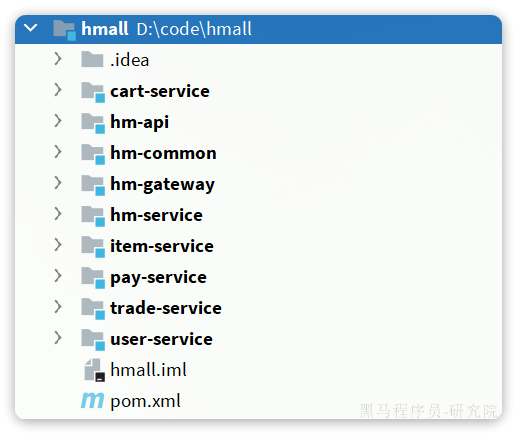

截图还展示 `hm-common`、`hm-api` 和 `hm-gateway` 等模块，这是课程整体工程的结构预览，不能据此认为本篇已经实现了网关、认证和全部服务。

本篇的具体拆分任务是：从 `hm-service` 中拆出 **`item-service` 商品服务**和 **`cart-service` 购物车服务**，再处理购物车对商品信息的依赖。


## 6. 拆分时机、高内聚与低耦合

拆分会增加基础设施和协作成本，需要先确认它解决什么问题。（课件第 25—26、34 页）

| 项目情况 | 课件建议 | 实际判断 |
| --- | --- | --- |
| 创业或探索阶段 | 单体优先，快速试错 | 业务边界与规模仍在变化 |
| 成熟业务逐渐扩大 | 逐步拆分 | 从发布瓶颈、热点和团队边界出发 |
| 目标明确的大型项目 | 可以直接采用微服务 | 仍需具备团队、运维与治理能力 |

**高内聚**：一个服务内的业务相互关联，能够形成完整能力。商品价格、状态和商品详情通常围绕商品领域共同演进。

**低耦合**：服务之间尽量减少对内部实现的依赖，只依赖必要、稳定的契约。购物车可以查询商品接口，但不直接引用商品服务的 Mapper。

| 拆分方式 | 含义 | 示例 |
| --- | --- | --- |
| 纵向拆分 | 按业务能力拆 | 商品、用户、购物车、交易 |
| 横向拆分 | 抽取跨业务复用的能力 | 短信、文件处理等公共能力 |

横向拆分不等于把所有业务统一拆成“Controller 服务、Service 服务、Mapper 服务”。这种按技术层跨进程切分通常破坏完整业务边界，增加调用链。

**补充**：以数据所有权检验边界。商品状态由商品服务管理，购物车不能因为原来能查同一张表，就继续跨服务直接写商品表。可以共享物理数据库实例以降低教学成本，但应明确逻辑库、表和访问权限的所有权。


## 7. 独立项目与 Maven 聚合工程

服务需要独立部署，但代码可以用不同方式组织。（课件第 28 页）

| 方式 | 结构 | 优点 | 需要管理的成本 |
| --- | --- | --- | --- |
| 独立 Project | 每个服务单独工程 | 团队边界和发布流程独立 | 公共依赖、版本和跨工程修改 |
| Maven 聚合 | 父工程组织多个 module | 统一依赖管理，教学和联调方便 | 控制模块依赖，避免重新耦合 |

**整理示例**：

```text
hmall/                         # 父工程，packaging=pom
├── pom.xml
├── hm-common/                 # 通用库，不独立启动
├── hm-api/                    # 远程契约库，后文介绍
├── item-service/              # 商品应用，独立启动
├── cart-service/              # 购物车应用，独立启动
└── hm-service/                # 尚未迁出的业务，按改造阶段处理
```

```xml
<packaging>pom</packaging>
<modules>
    <module>hm-common</module>
    <module>hm-api</module>
    <module>item-service</module>
    <module>cart-service</module>
</modules>
```

module 只是 Maven 的构建组织单位。一个项目拆成多个 module 后，如果仍只有一个启动入口、一个包整体部署，仍可能是模块化单体。真正的服务拆分还需要运行边界、数据边界和调用边界。

公共库通常发布普通 Jar；可执行服务按需要使用 Spring Boot 打包。不要把所有共享库都打成只能独立运行的可执行包。


## 8. 从 hm-service 拆出商品与购物车

课件第 29 页给出拆分目标，具体迁移不能只复制 Controller，还需处理依赖、配置与资源。

| 要迁移或检查的内容 | item-service | cart-service |
| --- | --- | --- |
| Controller | 商品查询和管理入口 | 购物车入口 |
| Service / 实现 | 商品业务 | 购物车业务 |
| Mapper / XML | 商品数据访问 | 购物车数据访问 |
| PO / DTO / VO | 商品实体及本服务对象 | 购物车实体及本服务对象 |
| 配置和启动类 | 商品应用独立配置 | 购物车应用独立配置 |
| 外部调用 | 暴露商品查询契约 | 通过远程接口获取商品信息 |

**整理迁移顺序**：

1. 创建独立 module、POM 和启动入口，复用经过管理的公共依赖。
2. 迁移本业务的 Controller、Service、Mapper、XML 和领域对象。
3. 调整包名、Mapper 扫描、XML namespace、别名和数据源配置。
4. 给服务分配应用名和本机联调端口，分别确认能够启动。
5. 找出原来的跨模块本地调用，改为远程接口。
6. 清理原应用中已迁出的重复入口与依赖，避免改造后双份实现继续演进。

**商品服务启动入口整理示例**：

```java
package com.hmall.item;

@SpringBootApplication
@MapperScan("com.hmall.item.mapper")
public class ItemApplication {
    public static void main(String[] args) {
        SpringApplication.run(ItemApplication.class, args);
    }
}
```

```yaml
server:
  port: 8081
spring:
  application:
    name: item-service
```

购物车服务可对应 `com.hmall.cart`、`CartApplication`、`cart-service`、端口 8080。这里的包名和端口是依据课件整理的示例，数据源等仍需按真实工程配置。

启动类默认扫描自身包及子包。迁移后公共配置可能位于扫描范围之外，应按需要显式导入；也不要为了“都能扫描到”而把其他服务的实现包一起扫描进来。


## 9. 购物车为什么需要远程查询商品

购物车保存的是“用户当时加入的商品与数量”，但展示时还需要商品当前价格、状态和库存。拆分后，这些最新信息属于商品服务。（课件第 31—32 页）

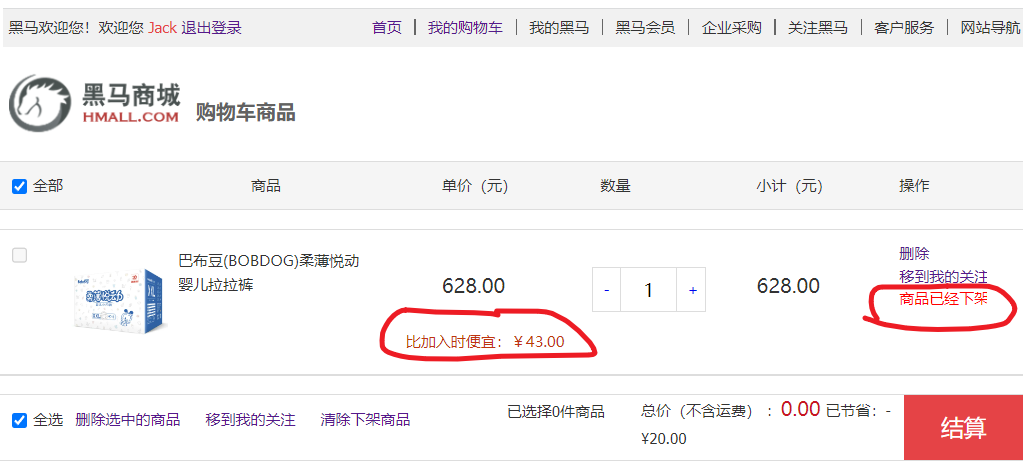

| 字段 | 来源与含义 |
| --- | --- |
| `CartVO.id` | 购物车记录 ID |
| `CartVO.itemId` | 对应商品 ID |
| `num` | 加入购物车的数量 |
| `price` | 购物车保存的原价格快照 |
| `newPrice` | 查询得到的当前商品价格 |
| `status / stock` | 当前商品状态与库存 |

课件示例中原价格为 `67100`，当前价格为 `62800`，页面显示 ¥671 与 ¥628，相差 ¥43，可按该示例理解为整数分。具体状态数值的含义应以工程枚举为准，不能凭 `1/2` 自行推断。

```text
查询购物车记录
    ↓ 收集 itemId、去重
批量调用商品查询接口
    ↓ 商品ID → 最新商品信息
回填 newPrice / status / stock
    ↓
返回购物车VO给前端
```

单体时可能直接调用 `itemService.listByIds(...)`。拆分为两个进程后，这个对象不在同一个 Spring 容器中，购物车不能再直接注入商品服务实现，需要跨网络调用。

优先一次批量查询多个商品，避免遍历购物车时每件商品都调用一次远程接口。购物车展示的结果仍只是查询时的快照，实际下单需再次校验价格、状态和库存。


## 10. 远程调用的契约与 DTO

一次 HTTP 调用要明确“调用哪个服务、哪个接口、传什么、返回什么”。（课件第 33、49 页）

| 要素 | 商品批量查询的整理约定 |
| --- | --- |
| 服务名 | `item-service` |
| 请求方法与路径 | GET `/items` |
| 查询参数 | `ids`，商品 ID 集合 |
| 返回类型 | `List<ItemDTO>` |
| 数据格式 | JSON |

**整理示例 DTO**：

```java
@Data
public class ItemDTO {
    private Long id;
    private Integer price;
    private Integer status;
    private Integer stock;
}
```

DTO 用于服务之间的数据交换，不应把数据库 PO、Mapper、完整内部实体一并暴露。返回字段、空值、缺失商品、错误响应等都属于契约。

**商品提供者接口整理示例**：

```java
@RestController
@RequestMapping("/items")
@RequiredArgsConstructor
public class ItemController {
    private final IItemService itemService;

    @GetMapping
    public List<ItemDTO> queryByIds(@RequestParam("ids") List<Long> ids) {
        if (ids == null || ids.isEmpty()) {
            return Collections.emptyList();
        }
        return itemService.listByIds(ids).stream()
            .map(ItemDTOConverter::from)
            .collect(Collectors.toList());
    }
}
```

`ItemDTOConverter.from` 是需自行实现的显式转换方法，不是框架内置。真实接口还应限制集合大小，并按工程规范校验参数。

课件第 33 页单个商品演示使用 `id`，第 49 页批量接口使用 `ids`；调用时必须按实际服务接口区分。若真实接口返回 `Result<List<ItemDTO>>` 这类统一包装，客户端也要使用对应结构，不能直接声明成列表。


## 11. RestTemplate：先看清 HTTP 调用

RestTemplate 可以直接发送 HTTP 请求，适合用来理解远程调用的基本组成。（课件第 33—34 页）

**课件步骤**：把 RestTemplate 注册为 Spring Bean，再发起请求。

**整理示例**，补充明确的连接与读取超时：

```java
@Configuration
public class HttpClientConfig {
    @Bean
    public RestTemplate restTemplate() {
        SimpleClientHttpRequestFactory factory =
            new SimpleClientHttpRequestFactory();
        factory.setConnectTimeout(2000);
        factory.setReadTimeout(3000);
        return new RestTemplate(factory);
    }
}
```

数值单位为毫秒，2 秒 / 3 秒只是整理示例，需要结合真实调用预算调整。

```java
public List<ItemDTO> queryItems(Collection<Long> itemIds) {
    if (itemIds == null || itemIds.isEmpty()) {
        return Collections.emptyList();
    }
    String ids = itemIds.stream()
        .map(String::valueOf)
        .collect(Collectors.joining(","));

    ResponseEntity<List<ItemDTO>> response = restTemplate.exchange(
        "http://localhost:8081/items?ids={ids}",
        HttpMethod.GET,
        null,
        new ParameterizedTypeReference<List<ItemDTO>>() {},
        Map.of("ids", ids));

    List<ItemDTO> body = response.getBody();
    if (body == null) {
        throw new IllegalStateException("商品查询响应体为空");
    }
    return body;
}
```

| `exchange` 参数 | 含义 |
| --- | --- |
| URL 模板 | 目标地址和 `{ids}` 占位 |
| `HttpMethod.GET` | 请求方法 |
| `HttpEntity<?>` | 请求头、请求体；本例为 `null` |
| 响应类型 | JSON 应转换成什么 Java 类型 |
| URI 变量 Map | 用值替换 URL 占位，不应混成任意字符串拼接 |

`ItemDTO.class` 适用于单个对象；集合用 `ParameterizedTypeReference<List<ItemDTO>>` 保留泛型类型信息，避免只得到没有元素类型约束的 List。

这里的 `localhost:8081` 只适用于服务在同一台主机按课件端口联调。容器内 `localhost` 指向当前容器，跨主机部署也不能把本机地址当成服务通用地址。


## 12. 购物车数据的批量组装

远程接口返回的商品列表通常不保证与购物车顺序一致。应按商品 ID 建立映射，再回填对应记录。

**整理示例**，此处 `queryItems` 是上一节的调用方法，后文可替换为 Feign Client：

```java
private void handleCartItems(List<CartVO> vos) {
    if (vos == null || vos.isEmpty()) {
        return;
    }
    Set<Long> itemIds = vos.stream()
        .map(CartVO::getItemId)
        .collect(Collectors.toSet());

    List<ItemDTO> items = queryItems(itemIds);
    Map<Long, ItemDTO> itemMap = items.stream()
        .collect(Collectors.toMap(ItemDTO::getId, Function.identity()));

    for (CartVO vo : vos) {
        ItemDTO item = itemMap.get(vo.getItemId());
        if (item == null) {
            throw new IllegalStateException("商品信息缺失: " + vo.getItemId());
        }
        vo.setNewPrice(item.getPrice());
        vo.setStatus(item.getStatus());
        vo.setStock(item.getStock());
    }
}
```

此整理示例采用严格完整性校验，假设响应中商品 ID 唯一且完整。真实购物车通常还需要定义“商品删除 / 失效时怎样展示”的规则，例如返回明确的失效标记，而不是把缺失商品继续当成有效商品。

| 容易写错的方式 | 问题 | 改进 |
| --- | --- | --- |
| 循环内逐件调用 | 网络请求次数随商品数增长 | 批量查询并去重 |
| 按列表下标一一对应 | 响应顺序未必相同 | 按商品 ID 关联 |
| 忽略缺失商品 | 可能使用过期状态或库存 | 明确失效或失败策略 |
| 把旧 `price` 覆盖为新价格 | 无法展示价格变化 | 保留快照，单独填 `newPrice` |


## 13. 硬编码地址遇到的治理问题

当商品服务从一个实例扩容为多个实例，或实例迁移、重启时，固定 `localhost:8081` 无法覆盖动态地址。（课件第 36 页）

```text
cart-service
    ↓ 应该调用谁？
item-service 实例A：8081
item-service 实例B：8082
item-service 实例C：8083
```

| 问题 | 需要的能力 |
| --- | --- |
| 实例地址会变化 | 注册与发现 |
| 同一服务有多个实例 | 负载均衡 |
| 实例可能下线或故障 | 健康状态维护与变更通知 |
| 发现之后仍可能调用失败 | 超时、错误处理与必要的保护 |

引入注册中心后，消费者通常面向逻辑服务名，而不是把每个实例 IP 写进业务代码。注册中心解决“有哪些可用实例”的问题，真正发送业务请求仍由消费者的客户端完成。


## 14. 注册中心与服务治理角色

消费者需要把稳定的服务名转换成动态的实例地址。注册中心维护“服务名 → 实例列表”，让地址变化不再要求业务代码跟着修改。（课件第 38—39 页）

| 角色 | 职责 | 本篇对应 |
| --- | --- | --- |
| 服务提供者 | 暴露接口，注册自己的地址与状态 | item-service |
| 服务消费者 | 发现目标服务，选择实例，发起调用 | cart-service |
| 注册中心 | 维护实例信息与健康状态，传播变化 | Nacos Server |

同一个服务可以同时是提供者和消费者，角色取决于某次调用关系。

```text
item-service:8081 ──注册──┐
item-service:8082 ──注册──┼──► Nacos
item-service:8083 ──注册──┘      │
                              │ 订阅 / 拉取实例列表
                              ▼
                         cart-service
                              │ 客户端选择一个实例
                              └────HTTP请求────► item-service:8082
```

**课件模型**：提供者注册并通过心跳续约报告状态；消费者订阅或拉取服务信息；状态改变后，注册中心更新列表并通知订阅者。

**版本边界**：健康维护、推送和连接方式取决于注册中心及客户端版本。Nacos 2.x 还涉及长连接等机制，不能把所有版本都简化成相同的 HTTP 心跳实现。

注册中心参与地址发现，业务请求通常由消费者直接发给提供者。服务发现与负载均衡也有分工：发现回答“有哪些实例”，负载均衡回答“这次选哪个实例”。

> 注册中心显示实例健康，不保证下一次调用一定成功。状态传播存在延迟，实例也可能在发现后故障，因此仍要配置超时并处理请求失败。

两个典型场景：商品服务扩容时，新实例注册后进入候选列表；实例下线时，列表更新后消费者不再选择它。具体生效时间取决于健康检测、通知和客户端缓存等环节。


## 15. Nacos 服务注册配置

Nacos 提供服务注册发现和配置管理。本篇使用的是**服务注册发现**，引入 discovery starter 不等于已经配置了远程配置中心。（课件第 41—43 页）

**课件依赖**：在需要注册或发现服务的应用中声明，版本由兼容的 BOM 管理。

```xml
<dependency>
    <groupId>com.alibaba.cloud</groupId>
    <artifactId>spring-cloud-starter-alibaba-nacos-discovery</artifactId>
</dependency>
```

**整理示例：商品服务 application.yml**。前提是 Nacos Server 已独立启动且应用能够访问。

```yaml
server:
  port: 8081
spring:
  application:
    name: item-service
  cloud:
    nacos:
      server-addr: "${NACOS_SERVER_ADDR:127.0.0.1:8848}"
```

购物车服务也引入同一 discovery 依赖并连接同一注册环境：

```yaml
server:
  port: 8080
spring:
  application:
    name: cart-service
  cloud:
    nacos:
      server-addr: "${NACOS_SERVER_ADDR:127.0.0.1:8848}"
```

| 配置 / 条件 | 作用与检查点 |
| --- | --- |
| `spring.application.name` | 服务的逻辑名称，调用方必须使用一致名称 |
| `server.port` | 当前应用监听的端口；同机多个实例要错开 |
| `server-addr` | Nacos 地址，不是商品服务地址 |
| namespace / group | 环境隔离维度；注册与发现需匹配 |
| 注册 IP 与端口 | 消费者必须能访问；能注册不代表业务地址可达 |
| 认证与网络 | 开启认证时配置对应凭据；开放实际需要的端口 |

这类 starter 通常通过自动配置完成注册发现，不必机械地额外添加 `@EnableDiscoveryClient`。是否需要注解仍应以实际依赖版本为准。

**同服务多实例**：再启动一个商品服务，应用名仍为 `item-service`，把启动参数改为 `--server.port=8082`。Nacos 服务列表应在同一服务下显示两个实例，而不是两个不同服务名。

课件的 Nacos 网站截图包含 2.2.3、1.4.6 等发布信息，这不能证明课程实际启动了其中某个版本。服务端、客户端和 Spring Cloud Alibaba 的版本需要一起核对。

**补充**：应用运行在容器里时，`127.0.0.1` 指向当前容器；应配置它能够访问的 Nacos 地址。使用 Nacos 2.x 客户端时，还可能需要对应的 gRPC 端口，例如默认主端口 8848 对应客户端 gRPC 端口 9848。控制台网页能打开，并不足以证明客户端通信已正常。


## 16. DiscoveryClient：发现与选择实例

有了注册信息，消费者就可以按 `item-service` 获取实例列表，再用选中的地址发送请求。（课件第 45、49 页）

`DiscoveryClient` 是 Spring Cloud 提供的发现抽象；具体 starter 负责连接相应注册中心。关键类型是 `org.springframework.cloud.client.discovery.DiscoveryClient` 与 `org.springframework.cloud.client.ServiceInstance`。

**整理示例**：替换第 11 节硬编码地址的查询方法，先检查空列表，再用随机算法演示实例选择。

```java
@Service
@RequiredArgsConstructor
public class ItemQueryService {
    private final DiscoveryClient discoveryClient;
    private final RestTemplate restTemplate;

    public List<ItemDTO> queryItems(Collection<Long> itemIds) {
        if (itemIds == null || itemIds.isEmpty()) {
            return Collections.emptyList();
        }
        List<ServiceInstance> instances =
            discoveryClient.getInstances("item-service");
        if (instances == null || instances.isEmpty()) {
            throw new IllegalStateException("没有可用的 item-service 实例");
        }

        int index = ThreadLocalRandom.current().nextInt(instances.size());
        ServiceInstance instance = instances.get(index);
        String ids = itemIds.stream()
            .map(String::valueOf)
            .collect(Collectors.joining(","));

        ResponseEntity<List<ItemDTO>> response = restTemplate.exchange(
            instance.getUri() + "/items?ids={ids}",
            HttpMethod.GET,
            null,
            new ParameterizedTypeReference<List<ItemDTO>>() {},
            Map.of("ids", ids));

        List<ItemDTO> body = response.getBody();
        if (body == null) {
            throw new IllegalStateException("商品查询响应体为空");
        }
        return body;
    }
}
```

课件使用 Hutool 的 `RandomUtil.randomInt`；整理示例改用 JDK 的 `ThreadLocalRandom`，避免为随机选实例额外引入工具库。随机选择只是演示，不包含完整的重试、熔断或故障隔离策略。

`getInstances` 返回发现客户端掌握的实例视图，不应理解为每次业务调用都必须同步访问一次 Nacos Server。获取方式与缓存行为取决于实现。

| 步骤 | 输入 | 输出 |
| --- | --- | --- |
| 服务发现 | `item-service` | 实例列表 |
| 实例选择 | 可用实例列表 | 一个 `ServiceInstance` |
| 组装请求 | 实例 URI、路径、参数 | HTTP 请求 |
| 响应转换 | JSON 与目标泛型 | `List<ItemDTO>` |

地址问题得到解决，但每个消费者仍需重复写实例选择、HTTP 请求和响应转换。OpenFeign 把这些通用步骤整合进接口代理。


## 17. OpenFeign 的声明式调用

业务代码更关心“查询哪些商品”，不应每个接口都重复组装 HTTP 请求。Spring Cloud OpenFeign 允许通过 Java 接口声明远程契约。（课件第 48—49 页）

**OpenFeign** 是开源的声明式 HTTP 客户端；**Spring Cloud OpenFeign** 将它整合进 Spring 应用，并提供对 Spring MVC 注解、服务发现与负载均衡等能力的支持。

```text
业务代码调用 ItemClient.queryItemByIds(ids)
    ↓
Feign 接口代理：解析服务名、方法、路径、参数和返回类型
    ↓
发现客户端提供实例列表，Spring Cloud LoadBalancer 选择实例
    ↓
底层 HTTP 客户端发送请求
    ↓
响应 JSON 转为 List<ItemDTO>，返回业务代码
```

| 组件 | 主要责任 |
| --- | --- |
| Nacos / DiscoveryClient | 提供服务实例信息 |
| Spring Cloud LoadBalancer | 选择本次调用的实例 |
| Spring Cloud OpenFeign | 解析接口契约，组织请求、编码与解码 |
| HTTP transport，例如 OkHttp | 实际网络通信与连接复用 |

这是同步调用：调用线程通常等待远程结果或异常。接口看起来像本地方法，网络超时、服务错误等远程调用边界仍然存在。


## 18. OpenFeign 入门与购物车改造

**课件入门步骤**：引入依赖 → 启用 Feign → 声明 Client → 注入并调用。（课件第 50—53 页）

消费者引入 OpenFeign 与 LoadBalancer；Nacos discovery 依赖保留：

```xml
<dependency>
    <groupId>org.springframework.cloud</groupId>
    <artifactId>spring-cloud-starter-openfeign</artifactId>
</dependency>
<dependency>
    <groupId>org.springframework.cloud</groupId>
    <artifactId>spring-cloud-starter-loadbalancer</artifactId>
</dependency>
```

**启用接口代理**。入门时先把 `ItemClient` 放在 `com.hmall.cart.client`，它位于启动类的子包中：

```java
package com.hmall.cart;

@EnableFeignClients
@SpringBootApplication
public class CartApplication {
    public static void main(String[] args) {
        SpringApplication.run(CartApplication.class, args);
    }
}
```

**声明远程契约**：

```java
package com.hmall.cart.client;

@FeignClient(name = "item-service")
public interface ItemClient {
    @GetMapping("/items")
    List<ItemDTO> queryItemByIds(@RequestParam("ids") Collection<Long> ids);
}
```

| 声明 | 对应 HTTP 含义 |
| --- | --- |
| `name = "item-service"` | 按此逻辑服务名发现实例 |
| `@GetMapping("/items")` | GET 请求与资源路径 |
| `@RequestParam("ids")` | 查询参数名，必须与服务端约定一致 |
| `Collection<Long>` | 商品 ID 集合 |
| `List<ItemDTO>` | JSON 响应的目标类型 |

**注入与调用的整理示例**：

```java
@Service
@RequiredArgsConstructor
public class CartItemQuery {
    private final ItemClient itemClient;

    public List<ItemDTO> queryItems(Collection<Long> ids) {
        if (ids == null || ids.isEmpty()) {
            return Collections.emptyList();
        }
        List<ItemDTO> items = itemClient.queryItemByIds(ids);
        if (items == null) {
            throw new IllegalStateException("商品查询响应体为空");
        }
        return items;
    }
}
```

独立演示可写 `itemClient.queryItemByIds(List.of(1L, 2L, 3L))`。这里用 `1L` 等 Long 字面量；课件的 `List.of(1, 2, 3)` 推断为 Integer 集合，与 `Collection<Long>` 不匹配。

购物车组装仍沿用第 12 节的规则：收集 ID、批量调用、按商品 ID 建立映射，再回填当前价格、状态和库存。改变的是查询实现，业务关联逻辑不需要重写。

**契约检查**：集合查询参数可能编码为重复键或逗号形式，取决于客户端契约与配置。服务端的参数绑定规则必须匹配实际请求，可在联调日志中核对。不要只凭 Java 方法签名判断线上的 URL。

本例没有设置 `@FeignClient.url`，因此按服务名发现实例。若显式设置固定 URL，寻址方式会改变，就不能再用它验证 Nacos 发现和多实例负载均衡。


## 19. HTTP 连接池与调用超时

每次建立 TCP 连接、进行 TLS 握手都会增加开销。连接池保存可复用连接，后续请求可以复用，从而减少建立连接的成本。（课件第 55—56 页）

| 课件列出的实现 | 理解要点 |
| --- | --- |
| HttpURLConnection | 课程中的默认实现；JVM 可能通过 keep-alive 复用连接 |
| Apache HttpClient | 支持可管理的连接池；不同 Feign 版本对应的集成不同 |
| OkHttp | 支持连接复用和连接池，课件选择此实现 |

课件将默认实现简写为“不支持连接池”，更准确的理解是没有与专用 HTTP 客户端等价的显式池管理能力，不能据此断言每次请求必然重新建立 TCP 连接。

**课件方案**：引入 OkHttp 集成并打开开关。

```xml
<dependency>
    <groupId>io.github.openfeign</groupId>
    <artifactId>feign-okhttp</artifactId>
</dependency>
```

**课件时代 OpenFeign 3.x 配置，补充超时示例**：

```yaml
feign:
  okhttp:
    enabled: true
  client:
    config:
      item-service:
        connectTimeout: 2000
        readTimeout: 3000
```

以上时间单位为毫秒。配置中的 `item-service` 与本篇 Client 名称一致。

| 参数 / 能力 | 解决的问题 | 不能直接等同于 |
| --- | --- | --- |
| 连接池 | 减少建立连接的开销 | 负载均衡 |
| 连接超时 | 限制建立连接的等待 | 整条业务链路总耗时 |
| 读取超时 | 限制等待响应数据的时间 | 服务端业务必然已停止 |
| 负载均衡 | 在多个实例中选择目标 | 单实例连接复用 |

**版本提示**：较新的 Spring Cloud OpenFeign 使用 `spring.cloud.openfeign` 前缀，例如 `spring.cloud.openfeign.okhttp.enabled`。不要把新版前缀直接混入本文的旧版配置。OpenFeign 4.x 的 Apache 集成也需要按 HttpClient 5 等实际支持核对。

加依赖不代表自动配置一定选择了它。可按课件提示，在调试时查看 `FeignBlockingLoadBalancerClient` 的 `delegate`，确认实际 HTTP 客户端；再结合连接、超时指标检查效果。连接池也不等于线程、请求队列和业务并发上限都已配置妥当。


## 20. 共享 Client 与 DTO 的模块设计

购物车、交易等多个消费者都查询商品时，分别复制 Client 和 DTO 会导致契约各自变化。课件建议由提供者维护独立的契约模块，统一复用。（课件第 58—61、66 页）

课件先展示按服务组织 `item-biz`、`item-api`、`item-dto` 等模块的思路，再展示教学项目统一的 `hm-api` 模块。

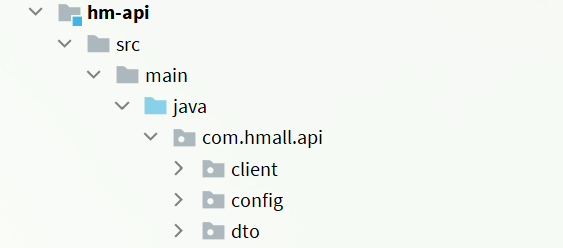

**课件最终组织方式的整理示例**：

```text
hmall/
├── hm-api/                         # 普通 Jar，提供远程契约
│   └── src/main/java/com/hmall/api/
│       ├── client/
│       │   └── ItemClient.java
│       ├── config/
│       │   └── DefaultFeignConfig.java
│       └── dto/
│           └── ItemDTO.java
├── item-service/                   # 商品实现与数据库访问
└── cart-service/                   # 依赖 hm-api，调用 ItemClient
```

| 共享模块可包含 | 服务实现应保留 |
| --- | --- |
| 对外 DTO 与明确的接口契约 | Mapper 与数据库 PO |
| Feign Client | 商品业务 Service 实现 |
| 必要的客户端配置 | 数据源、数据库迁移与内部规则 |

**依赖方向**：

```text
cart-service ──编译依赖──► hm-api
cart-service ──运行时HTTP──► item-service

item-service 可复用 hm-api 中的 DTO
cart-service 不应编译依赖 item-service 的业务实现
```

消费者在 POM 中声明 `hm-api` 的坐标，版本按真实父工程管理；这里不虚构课程完整的 groupId、version。`hm-api` 自身也要声明编译 Client 所需的 Feign / Spring 注解依赖，不能只创建目录就期待类可以编译。

共享 Jar 让编译期契约一致，但消费者部署后仍需访问真实的商品服务。删除远程实现、只保留 `hm-api`，无法完成商品查询。

**补充**：教学中统一 `hm-api` 管理简单；服务规模扩大后，可按商品、用户等领域分别发布契约，避免所有消费者因无关接口修改而同时升级。契约变化应尽量向后兼容，尤其注意字段删除、类型变化、参数重命名与响应包装变更。


## 21. 跨模块 Feign Client 的扫描

把接口从 `com.hmall.cart.client` 移到 `com.hmall.api.client` 后，它不再位于 `CartApplication` 所在包的子包内。仅写默认的 `@EnableFeignClients`，可能找不到这个接口。（课件第 62 页）

**方式一：显式指定包**，适合启用一组客户端：

```java
@EnableFeignClients(basePackages = "com.hmall.api.client")
@SpringBootApplication
public class CartApplication {
    public static void main(String[] args) {
        SpringApplication.run(CartApplication.class, args);
    }
}
```

**方式二：显式指定接口**，适合只启用本应用需要的客户端：

```java
@EnableFeignClients(clients = {ItemClient.class})
```

二选一即可。第二种写在启动配置类上，并 import 共享模块的 `com.hmall.api.client.ItemClient`。

| 检查项 | 常见失败原因 |
| --- | --- |
| module 依赖 | 消费者没有引入 hm-api，类不在运行时 classpath |
| Feign 扫描 | 指定的包不包含真实接口 |
| 注解 | 接口未标注 `@FeignClient` |
| 普通组件扫描 | 把 `@ComponentScan` 与 Feign 接口代理注册混为一谈 |

> 课件第 61 页截图是单数 `client`，第 62 页示例写成复数 `clients`。应以实际 Java 的 package 声明为准。本篇统一使用 `com.hmall.api.client`。

场景一：购物车要使用共享模块里的全部 Client，可以指定包。场景二：服务只依赖商品查询契约，可以指定 `ItemClient.class`，减少无关客户端被注册。


## 22. Feign 日志的两个开关与作用范围

接口调用失败时，需要看到实际请求路径、参数、状态码和耗时。Feign 日志由**日志框架等级**和 **Feign 自身记录等级**共同决定。（课件第 64—65 页）

| Feign 等级 | 输出内容 |
| --- | --- |
| NONE | 不记录，是默认值 |
| BASIC | 请求方法、URL、响应状态码与耗时 |
| HEADERS | BASIC 加请求和响应头 |
| FULL | HEADERS 加请求体、响应体及更多明细 |

**第一个开关：将 Client 的日志类别设为 DEBUG**。

```yaml
logging:
  level:
    com.hmall.api.client.ItemClient: DEBUG
```

也可以配置客户端所在包，但会影响该包下的所有 Client。

**第二个开关：配置 `feign.Logger.Level` Bean**。关键 import 是 `feign.Logger`，不是 `org.slf4j.Logger`。

```java
package com.hmall.api.config;

import feign.Logger;
import org.springframework.context.annotation.Bean;

public class DefaultFeignConfig {
    @Bean
    public Logger.Level feignLogLevel() {
        return Logger.Level.FULL;
    }
}
```

**局部生效**，只为某个 Client 引入配置：

```java
@FeignClient(
    name = "item-service",
    configuration = DefaultFeignConfig.class
)
public interface ItemClient {
    @GetMapping("/items")
    List<ItemDTO> queryItemByIds(@RequestParam("ids") Collection<Long> ids);
}
```

**全局默认配置**，在启用 Feign 的配置类上声明：

```java
@EnableFeignClients(
    basePackages = "com.hmall.api.client",
    defaultConfiguration = DefaultFeignConfig.class
)
```

| 现象 | 原因或检查方向 |
| --- | --- |
| 配置 DEBUG 仍看不到 Feign 请求 | Feign 记录等级可能仍为 NONE |
| 返回 FULL 仍没有日志 | Client 对应的日志类别可能未开启 DEBUG |
| 只写了配置类，却没有注册 | 类没有被 Feign 配置引入或 Spring 扫描 |
| 只想局部配置，却影响其他 Client | 配置类可能已被主应用扫描为全局 Bean |

整理示例故意不加 `@Configuration`，通过 Feign 的 `configuration` / `defaultConfiguration` 引入。它仍会在相应 Feign 配置上下文中处理 `@Bean` 方法；若改成主容器扫描到的配置类，则要重新检查影响范围。

FULL 适合本地联调，但可能记录 Authorization、Cookie、用户信息与大响应体。生产环境应按需要选择等级、限制日志量并脱敏，避免为排查一次调用长期保留全部正文。


## 23. 远程调用的失败边界

服务拆分后，调用方与被调用方处于不同进程。一次失败可能发生在发现、连接、响应或业务处理阶段，不能把所有异常都当成“查不到商品”。

**补充/改进**：

| 失败位置 | 典型表现 | 应对原则 |
| --- | --- | --- |
| 无可用实例 | 发现列表为空，无法选择目标 | 检查注册、环境隔离和实例健康 |
| 网络不可达 | 连接拒绝、连接超时 | 检查注册地址、端口、路由和防火墙 |
| 处理过慢 | 读取超时 | 排查慢 SQL、线程拥塞和下游延迟 |
| HTTP 错误 | 4xx / 5xx、Feign 异常 | 区分参数、权限和服务端错误 |
| 响应结构变化 | JSON 转换失败或字段为空 | 核对 DTO、泛型与响应包装 |
| 业务数据缺失 | 部分商品没有返回 | 按契约标记失效或明确失败 |

**失败不能伪装成正常空列表**。如果商品服务不可用时统一返回空列表，购物车可能误以为用户的商品全部失效。降级值必须有业务含义，并让调用方能区分真实无数据与下游异常。

**超时不代表服务端没有执行**。商品查询通常较容易重试；创建订单、扣库存、支付等写操作则需先设计幂等性，即同一业务请求重复提交仍只产生一次有效结果。不要给所有 Feign 调用统一加无限重试。

本篇只建立这些判断边界。熔断、降级、限流与跨服务事务需要后续专题，不会因为使用 Feign 或 Nacos 就自动完成。


## 24. 联调顺序与故障定位

按层验证能区分“服务没启动”“注册没完成”和“Feign 契约不匹配”。以下是读者在自己的工程中操作时的验证步骤，本篇没有实际启动课程服务。

1. **提供者接口**：先直接访问商品服务，确认参数与返回结构，例如：

   ```text
   http://localhost:8081/items?ids=1,2,3
   ```

2. **注册发现**：查看 Nacos 中 `item-service` 与 `cart-service` 的注册情况；核对实例 IP、端口、namespace、group，并从消费者运行环境确认地址可达。
3. **Feign 契约**：确认依赖、扫描范围、服务名、GET 路径、`ids` 参数与 DTO 一致；在本地打开适当日志，检查实际请求。
4. **完整业务**：查询购物车，确认旧价格保留、当前价格回填，商品顺序变化时仍能按 ID 正确关联，并处理缺失商品。
5. **多实例**：以相同应用名启动 8081 / 8082 两个商品实例，通过提供者访问日志观察选择结果。不要仅凭一次响应推断负载均衡算法或均匀程度。
6. **失败场景**：停止一个实例，等待注册发现状态传播后继续访问；再检查所有提供者不可用、商品缺失和响应超时时的处理。多实例本身不等于任意故障下请求都成功。

| 现象 | 优先检查 |
| --- | --- |
| 启动报缺少 `ItemClient` Bean | hm-api 依赖、`@EnableFeignClients` 与真实包名 |
| 提示没有可用服务实例 | 服务名、Nacos 地址、namespace / group、健康状态 |
| Nacos 有实例但连接失败 | 实例注册 IP 与端口是否能被消费者访问 |
| 直接调用成功，Feign 404 | 方法、路径、服务端 context path 是否一致 |
| 返回 400 | 参数名、类型、集合编码和必要参数 |
| 反序列化失败 | 返回列表还是统一包装，字段类型是否一致 |
| OkHttp 或超时配置没生效 | 实际 OpenFeign 版本、配置前缀、Client 名称与 transport |
| 日志没有输出 | DEBUG 与 `Logger.Level` 两个开关、配置作用范围 |


## 25. 核心回顾与面试提示

本篇围绕一条调用链：购物车需要商品当前信息 → 拆分后使用 HTTP 查询 → Nacos 维护动态实例 → LoadBalancer 选择实例 → Feign 用接口表达请求 → HTTP 客户端完成传输。

| 判断点 | 应掌握的结论 |
| --- | --- |
| 单体与微服务 | 根据业务、团队和独立发布需求取舍 |
| 服务边界 | 按完整业务能力拆分，保持高内聚、低耦合 |
| module 与服务 | Maven 模块划分不等于独立运行、部署与自治 |
| 数据边界 | 各服务管理自己的数据，通过契约协作 |
| 注册中心 | 维护实例信息，通常不代理业务 HTTP 请求 |
| 发现与负载均衡 | 获取实例列表与选择实例是不同职责 |
| Feign | 声明式 HTTP 客户端，调用仍可能超时或失败 |
| 连接池 | 复用连接，需确认实际底层实现与版本配置 |
| 共享契约 | 复用 Client / DTO，避免依赖提供者内部实现 |
| 扫描与日志 | 显式核对 Client 包名；日志需要 DEBUG 与非 NONE 等级 |

**面试提示**：能用“购物车查商品”的例子说明服务拆分后本地调用为何失效；分别说清 Nacos、LoadBalancer、Feign 和 OkHttp 的职责；解释为什么注册健康不保证调用成功、为什么 Feign 共享包需要显式扫描，以及为什么远程写操作重试前必须考虑幂等性。回答时带上服务名、接口契约、实例地址与超时这些具体边界。
